In [1]:
#Cell 1: installs packages and libraries if they are not already installed
import sys
!{sys.executable} -m pip install pennylane pennylane-qiskit qiskit-ibm-runtime qiskit-aer librosa scikit-learn torch matplotlib numpy pandas --quiet
print("Packages ready")

Packages ready


In [2]:
#Cell 2: downloads the ESC-50 dataset(sounds) from github if it is not already downloaded
import urllib.request
import zipfile
import os

if not os.path.exists("ESC-50-master"):
    print("Downloading ESC-50 dataset...")
    urllib.request.urlretrieve("https://github.com/karoldvl/ESC-50/archive/master.zip", "ESC-50.zip")
    with zipfile.ZipFile("ESC-50.zip", "r") as z:
        z.extractall(".")
    print("Done")
else:
    print("Dataset already exists")

Done


In [3]:
#Cell 3: processes the audio files, extracts features, and saves them as numpy arrays
import numpy as np
import os
import librosa  #audio loading extraction
import pandas as pd #filters dataset
from sklearn.preprocessing import LabelEncoder, StandardScaler #converts names to numbers
from sklearn.decomposition import PCA #compresses features(20->4)

DATASET_PATH = "ESC-50-master/audio"
META_PATH    = "ESC-50-master/meta/esc50.csv"
N_MFCC       = 20
N_QUBITS     = 4
ANIMAL_CATS  = ["dog", "cat", "frog", "crow"]

meta = pd.read_csv(META_PATH)
meta = meta[meta["category"].isin(ANIMAL_CATS)].reset_index(drop=True)
print(f"Found {len(meta)} clips across {meta['category'].nunique()} classes") #clips = classes * clips per class

#feature extraction
def extract_mfcc(filepath, n_mfcc=N_MFCC):
    """Load audio clip and return mean MFCC vector."""
    y, sr = librosa.load(filepath, sr=22050, duration=5.0)
    mfcc  = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=n_mfcc)
    return np.mean(mfcc, axis=1)

features, labels = [], []
for _, row in meta.iterrows():
    filepath = os.path.join(DATASET_PATH, row["filename"])
    try:
        mfcc = extract_mfcc(filepath)
        features.append(mfcc)
        labels.append(row["category"])
    except Exception as e:
        print(f"Skipping {row['filename']}: {e}")

X = np.array(features)
le = LabelEncoder()
y  = le.fit_transform(labels)

scaler   = StandardScaler()
X_scaled = scaler.fit_transform(X)
pca      = PCA(n_components=N_QUBITS)
X_pca    = pca.fit_transform(X_scaled)

np.save("X_features.npy",  X_pca)
np.save("y_labels.npy",    y)
np.save("class_names.npy", le.classes_)

print(f"Features shape: {X_pca.shape}")
print(f"Classes: {list(le.classes_)}")
print(f"Variance: {pca.explained_variance_ratio_.sum():.1%}")
print("Saved")

Found 160 clips across 4 classes
Features shape: (160, 4)
Classes: [np.str_('cat'), np.str_('crow'), np.str_('dog'), np.str_('frog')]
Variance: 58.4%
Saved


In [4]:
#Cell 4: prepares the data for training and testing, and creates a PyTorch DataLoader for the training set
import torch
from torch.utils.data import DataLoader, TensorDataset #PyTorch utilities for batching and dataset handling
from sklearn.model_selection import train_test_split    #Splits data into training and testing sets

X          = np.load("X_features.npy")
y          = np.load("y_labels.npy")
class_names = np.load("class_names.npy", allow_pickle=True)

#Train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

X_train_t = torch.tensor(X_train, dtype=torch.float32)
X_test_t  = torch.tensor(X_test,  dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.long)
y_test_t  = torch.tensor(y_test,  dtype=torch.long)

# Normalize to [-π, π] for angle encoding
scale     = X_train_t.abs().max()
X_train_t = torch.pi * (X_train_t / scale)
X_test_t  = torch.pi * (X_test_t  / scale)

#Create DataLoader for training
train_loader = DataLoader(
    TensorDataset(X_train_t, y_train_t),
    batch_size=16, shuffle=True
)

N_CLASSES = len(class_names)
print(f"Train: {len(X_train)} | Test: {len(X_test)} | Classes: {N_CLASSES}")

Train: 128 | Test: 32 | Classes: 4


In [5]:
#Cell 5: builds the quantum circuit, creates a PennyLane TorchLayer, and builds Quantum simulator
import pennylane as qml #quantum computing framework
import torch.nn as nn #neural network blocks

N_LAYERS = 3

dev_sim = qml.device("default.qubit", wires=N_QUBITS)

#Builds the quantum circuit with angle encoding and variational layers, and returns expectation values for each qubit
@qml.qnode(dev_sim, interface="torch")
def quantum_circuit(inputs, weights):
    """Encode audio features and apply variational layers."""
    #Where angle encoding happens
    qml.AngleEmbedding(inputs, wires=range(N_QUBITS), rotation="Y")
    qml.StronglyEntanglingLayers(weights, wires=range(N_QUBITS))
    return [qml.expval(qml.PauliZ(i)) for i in range(N_QUBITS)]

weight_shapes = {"weights": qml.StronglyEntanglingLayers.shape(N_LAYERS, N_QUBITS)}
qlayer_sim    = qml.qnn.TorchLayer(quantum_circuit, weight_shapes)

#Builds the full simulation by combining the quantum layer with classical layers for classification
class HybridModel(nn.Module):
    """Hybrid quantum-classical model for animal sound classification."""
    def __init__(self, qlayer):
        super().__init__()
        self.quantum   = qlayer
        self.classical = nn.Sequential(
            nn.Linear(N_QUBITS, 16),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(16, N_CLASSES)
        )

    def forward(self, x):
        x = self.quantum(x)
        x = self.classical(x)
        return x

model_sim = HybridModel(qlayer_sim)
print("Simulator model ready")
print(f"Total parameters: {sum(p.numel() for p in model_sim.parameters())}")

Simulator model ready
Total parameters: 184


In [6]:
#Cell 6: trains the hybrid model on the quantum simulator, evaluates it on the test set, and saves the trained weights
import matplotlib.pyplot as plt

EPOCHS  = 50 #number of times to loop through the training data
LR      = 0.005 
loss_fn = nn.CrossEntropyLoss()
opt     = torch.optim.Adam(model_sim.parameters(), lr=LR)

train_losses, train_accs = [], []
print(f"Training on simulator for {EPOCHS} epochs...\n")

for epoch in range(EPOCHS):
    model_sim.train()
    epoch_loss, correct, total = 0.0, 0, 0

    for X_batch, y_batch in train_loader:
        opt.zero_grad()
        outputs = model_sim(X_batch)
        loss    = loss_fn(outputs, y_batch)
        loss.backward()
        opt.step()

        epoch_loss += loss.item()
        correct    += (outputs.argmax(1) == y_batch).sum().item()
        total      += y_batch.size(0)

    avg_loss = epoch_loss / len(train_loader)
    accuracy = correct / total * 100
    train_losses.append(avg_loss)
    train_accs.append(accuracy)

    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch+1:02d}/{EPOCHS} | Loss: {avg_loss:.4f} | Acc: {accuracy:.1f}%")

model_sim.eval()
with torch.no_grad():
    sim_outputs = model_sim(X_test_t)
    sim_preds   = sim_outputs.argmax(1)
    sim_acc     = (sim_preds == y_test_t).sum().item() / len(y_test_t) * 100

print(f"\nSimulator test accuracy: {sim_acc:.1f}%")

torch.save(model_sim.state_dict(), "trained_weights.pt")
print("Weights saved to trained_weights.pt")

Training on simulator for 50 epochs...

Epoch 10/50 | Loss: 1.2451 | Acc: 48.4%
Epoch 20/50 | Loss: 0.9541 | Acc: 57.0%
Epoch 30/50 | Loss: 0.8533 | Acc: 69.5%
Epoch 40/50 | Loss: 0.8026 | Acc: 66.4%
Epoch 50/50 | Loss: 0.7930 | Acc: 69.5%

Simulator test accuracy: 56.2%
Weights saved to trained_weights.pt


In [7]:
#Cell 7: connects to IBM Quantum hardware
import qiskit
import pylatexenc
import qiskit_machine_learning

In [8]:
#Cell 8: checks the version of qiskit-ibm-runtime
import qiskit_ibm_runtime
print(qiskit_ibm_runtime.__version__)

0.45.1


In [ ]:
#Cell 9: lists available IBM Quantum backends
from qiskit_ibm_runtime import QiskitRuntimeService

#enter your IBM API token here to connect to the IBM Quantum cloud and list available backends
service = QiskitRuntimeService(
    channel="ibm_cloud",
    token="Enter your IBM API token here"
)

print("Connected")
backends = service.backends()
for b in backends:
    print(f"{b.name} | {b.num_qubits} qubits")

qiskit_runtime_service._discover_account:WARNING:2026-05-11 23:34:22,331: Loading account with the given token. A saved account will not be used.
qiskit_runtime_service.__init__:WARNING:2026-05-11 23:34:27,650: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService().
qiskit_runtime_service.backends:WARNING:2026-05-11 23:34:27,650: Loading instance: open-instance, plan: open


Connected
ibm_fez | 156 qubits
ibm_marrakesh | 156 qubits
ibm_kingston | 156 qubits


In [10]:
#Cell 10: creates a PennyLane Qiskit device and quantum circuit for hardware execution
import sys
!{sys.executable} -m pip install pennylane-qiskit --quiet
print("Done")

Done


In [11]:
#Cell 11: creates a PennyLane Qiskit device and quantum circuit for hardware execution
from qiskit_ibm_runtime import QiskitRuntimeService
import pennylane as qml
backend = service.least_busy(
    operational=True,
    simulator=False,
    min_num_qubits=N_QUBITS
)
print(f"Auto-selected: {backend.name}")
print(f"Queue: {backend.status().pending_jobs} jobs ahead of you")
dev_hw = qml.device(
    "qiskit.remote",
    wires=N_QUBITS,
    backend=backend,  
    shots=256
)
print(f"Connected to {backend.name}!")

qiskit_runtime_service.backends:WARNING:2026-05-11 23:36:00,953: Loading instance: open-instance, plan: open
qiskit_runtime_service.backends:WARNING:2026-05-11 23:36:02,836: Using instance: open-instance, plan: open


Auto-selected: ibm_kingston
Queue: 11 jobs ahead of you


c:\Users\coryt\anaconda3\envs\quantum-audio\Lib\site-packages\pennylane\devices\device_api.py:201: PennyLaneDeprecationWarning: Setting shots on device is deprecated. Please use the `set_shots` transform on the respective QNode instead.
  warnings.warn(


Connected to ibm_kingston!


In [12]:
#Cell 12: executes the quantum circuit on real hardware using the trained weights, evaluates accuracy, and saves results
@qml.qnode(dev_hw, interface="torch")
def quantum_circuit_hw(inputs, weights):
    """Same circuit on real quantum hardware."""
    qml.AngleEmbedding(inputs, wires=range(N_QUBITS), rotation="Y")
    qml.StronglyEntanglingLayers(weights, wires=range(N_QUBITS))
    return [qml.expval(qml.PauliZ(i)) for i in range(N_QUBITS)]

weight_shapes = {"weights": qml.StronglyEntanglingLayers.shape(N_LAYERS, N_QUBITS)}
qlayer_hw     = qml.qnn.TorchLayer(quantum_circuit_hw, weight_shapes)
model_hw      = HybridModel(qlayer_hw)

model_hw.load_state_dict(torch.load("trained_weights.pt"), strict=False)
print("Weights loaded")

N_HW_SAMPLES = 5
X_hw = X_test_t[:N_HW_SAMPLES]
y_hw = y_test_t[:N_HW_SAMPLES]

print(f"Sending {N_HW_SAMPLES} samples to {backend.name}...")
print("This will take a few minutes, do not close program\n")

model_hw.eval()
with torch.no_grad():
    hw_outputs = model_hw(X_hw)
    hw_preds   = hw_outputs.argmax(1)
    hw_acc     = (hw_preds == y_hw).sum().item() / N_HW_SAMPLES * 100

np.save("hw_predictions.npy", hw_preds.numpy())
np.save("hw_actual.npy",      y_hw.numpy())

print(f"Hardware accuracy:  {hw_acc:.1f}%")
print(f"Predicted: {[class_names[p] for p in hw_preds.numpy()]}")
print(f"Actual:    {[class_names[l] for l in y_hw.numpy()]}")
print("Results saved")

Weights loaded
Sending 5 samples to ibm_kingston...
This will take a few minutes, do not close program

Hardware accuracy:  40.0%
Predicted: [np.str_('crow'), np.str_('dog'), np.str_('frog'), np.str_('crow'), np.str_('cat')]
Actual:    [np.str_('frog'), np.str_('dog'), np.str_('crow'), np.str_('crow'), np.str_('crow')]
Results saved


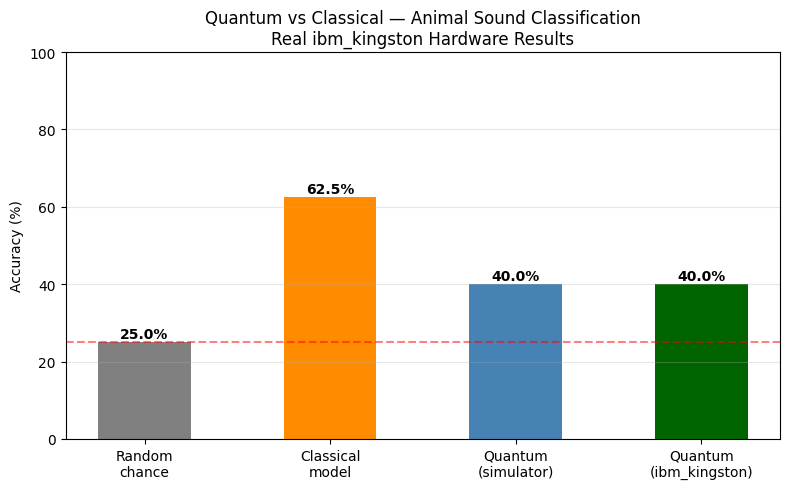

Saved as final_hardware_results.png


In [13]:
#Cell 13: visualizes the results by comparing the quantum simulator and real hardware accuracies against classical and random baselines
import matplotlib.pyplot as plt

model_sim.eval()
with torch.no_grad():
    sim_preds_5 = model_sim(X_hw).argmax(1)
    sim_acc_5   = (sim_preds_5 == y_hw).sum().item() / N_HW_SAMPLES * 100

fig, ax = plt.subplots(figsize=(8, 5))

categories = ["Random\nchance", "Classical\nmodel", "Quantum\n(simulator)", f"Quantum\n({backend.name})"]
accuracies  = [25.0, 62.5, sim_acc_5, hw_acc]
colors      = ["gray", "darkorange", "steelblue", "darkgreen"]

bars = ax.bar(categories, accuracies, color=colors, width=0.5)
ax.set_ylim(0, 100)
ax.set_ylabel("Accuracy (%)")
ax.set_title(f"Quantum vs Classical — Animal Sound Classification\nReal {backend.name} Hardware Results")
ax.axhline(y=25, color="red", linestyle="--", alpha=0.5)
ax.grid(True, alpha=0.3, axis="y")

for bar, acc in zip(bars, accuracies):
    ax.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 1,
        f"{acc:.1f}%", ha="center", fontweight="bold"
    )

plt.tight_layout()
plt.savefig("final_hardware_results.png", dpi=150)
plt.show()
print("Saved as final_hardware_results.png")